# TP 3 — K-means : les manchots de l'Antarctique

---
##  Contexte et objectif du TP
Jusqu'ici (TP 2), nous faisions de l'**apprentissage supervisé** : on connaissait la bonne réponse (comestible / toxique)
et le modèle apprenait à la retrouver. Ici, nous faisons de l'**apprentissage non supervisé** : on **cache l'espèce**
des manchots et on demande à l'algorithme **K-means** de trouver tout seul des **groupes** (clusters) à partir de 4 mesures
(longueur et profondeur du bec, longueur de nageoire, masse).

Ce TP a pour but de :
1. comprendre **comment fonctionne K-means** et pourquoi il faut **mettre les variables à l'échelle** ;
2. apprendre à **choisir le nombre de groupes k** (méthode du coude et score de silhouette) ;
3. **vérifier** si les groupes trouvés correspondent aux vraies espèces (Adelie, Chinstrap, Gentoo) ;
4. refaire l'expérience avec **Orange**.

Les données ont été collectées par Kristen Gorman (2007–2009) sur trois îles de l'archipel Palmer : 344 manchots.

| Partie | Contenu | Points |
|---|---|---|
| **A** | Découvrir les données | 3 |
| **B** | K-means avec Python | 13 |
| **C** | K-means avec Orange | 4 |

##  Rappel : l'algorithme K-means
1. Choisir **k** et placer k **centres** (centroïdes) au hasard.
2. **Affecter** chaque point au centre le plus proche (distance euclidienne).
3. **Déplacer** chaque centre à la **moyenne** de ses points.
4. Recommencer 2 et 3 jusqu'à ce que les groupes ne changent plus.

L'**inertie** = somme des distances au carré de chaque point à son centre. Elle **diminue à chaque étape**.

##  Livrables
Ce notebook exécuté (`.ipynb`) et le fichier Orange (`.ows`).

## 📖 Mini-glossaire
| Terme | Signification | Pourquoi on en a besoin |
|---|---|---|
| **Importation** | Charger les bibliothèques et le fichier de données | Point de départ de tout projet |
| **Exploration / Visualisation** | Compter, tracer, repérer valeurs manquantes et groupes | Comprendre les données avant de calculer |
| **Nettoyage** | Supprimer ou corriger les lignes inutilisables (valeurs manquantes) | K-means ne sait pas calculer avec des cases vides |
| **Standardisation (mise à l'échelle)** | Transformer chaque variable pour avoir moyenne 0 et écart-type 1 | Sinon la variable aux grandes valeurs (la masse en grammes) écrase les autres dans le calcul des distances |
| **Entraînement (fit)** | L'algorithme cherche les centres et les groupes | C'est l'apprentissage |
| **Inertie** | Somme des carrés des distances aux centres : mesure la « compacité » des groupes | Elle baisse toujours quand k augmente → on cherche un « coude » |
| **Silhouette** | Score entre −1 et 1 : un point est-il bien dans son groupe et loin des autres ? | Plus il est proche de 1, mieux les groupes sont séparés |
| **Indice de Rand ajusté (ARI)** | Accord entre les groupes trouvés et les vraies espèces (1 = parfait, 0 = hasard) | Mesurer si K-means a « retrouvé » les espèces **sans les connaître** |
| **Interprétation** | Décrire et nommer les groupes (moyennes, espèce dominante) | Un groupe n'a de sens que si on sait ce qu'il représente |

## 0. Importation des bibliothèques et du fichier

**Importation** : on charge les outils.
* `pandas` / `numpy` : tableaux et calculs ;
* `matplotlib` : graphiques ;
* `StandardScaler` : standardisation ; `KMeans` : l'algorithme ;
* `silhouette_score`, `adjusted_rand_score` : mesures de qualité.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

pd.set_option("display.max_columns", 30)
print("Bibliothèques importées ✅")

Bibliothèques importées ✅


---
# PARTIE A — Découvrir · *3 points*
**But** : faire connaissance avec les données et vérifier visuellement qu'il existe bien des groupes à trouver.

## A.1 — Premier contact
### Importation et exploration
*Pourquoi ?* On doit connaître les colonnes, le nombre de manchots par espèce et surtout les **valeurs manquantes**,
car K-means ne les accepte pas.

In [3]:
manchots = pd.read_csv("manchots.csv")                  # importation
print("Dimensions :", manchots.shape)
display(manchots.head())
print("Colonnes :", list(manchots.columns))
print("\nTypes :\n", manchots.dtypes)

Dimensions : (344, 7)


,espece,ile,longueur_bec_mm,profondeur_bec_mm,longueur_nageoire_mm,masse_g,sexe
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,femelle
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,femelle
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,femelle


Colonnes : ['espece', 'ile', 'longueur_bec_mm', 'profondeur_bec_mm', 'longueur_nageoire_mm', 'masse_g', 'sexe']

Types :
 espece                   object
ile                      object
longueur_bec_mm         float64
profondeur_bec_mm       float64
longueur_nageoire_mm    float64
masse_g                 float64
sexe                     object
dtype: object


### Configuration des noms de colonnes
⚠️ Les noms exacts peuvent varier selon votre fichier. La cellule ci-dessous essaie de les **détecter automatiquement** ;
**vérifiez l'affichage** et corrigez à la main si besoin.

In [4]:
# Colonne de l'espèce (la "vraie" réponse, qu'on ne donnera PAS à K-means)
ESPECE = next(c for c in manchots.columns if "esp" in c.lower() or "species" in c.lower())

# Les 4 mesures = colonnes numériques (on enlève une éventuelle colonne année)
MESURES = [c for c in manchots.select_dtypes(include="number").columns if "ann" not in c.lower() and "year" not in c.lower()]

# Colonnes bec : longueur et profondeur (utiles pour les graphiques)
def trouver(mots_cles, defaut):
    for c in MESURES:
        if all(any(m in c.lower() for m in groupe) for groupe in mots_cles):
            return c
    return defaut
BEC_LONG = trouver([["bec", "bill"], ["long", "length"]], MESURES[0])
BEC_PROF = trouver([["bec", "bill"], ["prof", "depth"]], MESURES[1])

print("Espèce      :", ESPECE)
print("4 mesures   :", MESURES)
print("Bec longueur / profondeur :", BEC_LONG, "/", BEC_PROF)
assert len(MESURES) == 4, "Il doit y avoir 4 mesures : corriger MESURES à la main."

Espèce      : espece
4 mesures   : ['longueur_bec_mm', 'profondeur_bec_mm', 'longueur_nageoire_mm', 'masse_g']
Bec longueur / profondeur : longueur_bec_mm / profondeur_bec_mm


### Manchots par espèce et valeurs manquantes

Manchots par espèce :
espece
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Valeurs manquantes par colonne :
espece                   0
ile                      0
longueur_bec_mm          2
profondeur_bec_mm        2
longueur_nageoire_mm     2
masse_g                  2
sexe                    11
dtype: int64


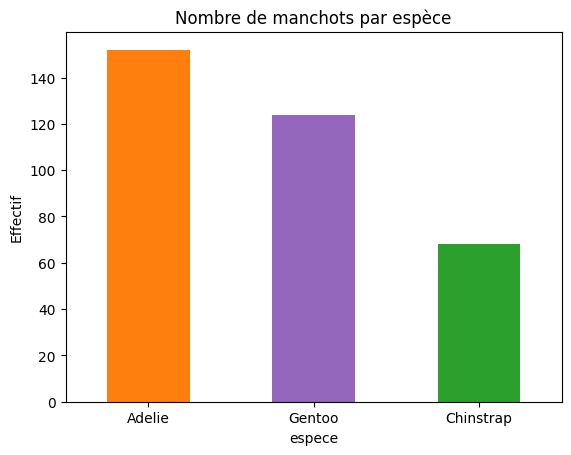

In [5]:
print("Manchots par espèce :")
print(manchots[ESPECE].value_counts())

print("\nValeurs manquantes par colonne :")
print(manchots.isna().sum())

manchots[ESPECE].value_counts().plot(kind="bar", rot=0, color=["tab:orange", "tab:purple", "tab:green"])
plt.title("Nombre de manchots par espèce")
plt.ylabel("Effectif")
plt.show()

### Nettoyage
On **supprime les lignes dont l'une des 4 mesures manque** (consigne de l'énoncé).
`dropna(subset=MESURES)` ne regarde que ces 4 colonnes : un manchot dont seul le sexe est inconnu est conservé.
*Pourquoi ?* Une case vide empêcherait le calcul des distances.

In [6]:
avant = len(manchots)
df = manchots.dropna(subset=MESURES).reset_index(drop=True)
print(f"Lignes avant : {avant} | après : {len(df)} | supprimées : {avant - len(df)}")
print("Valeurs manquantes dans les mesures :", int(df[MESURES].isna().sum().sum()))
print(df[ESPECE].value_counts())

Lignes avant : 344 | après : 342 | supprimées : 2
Valeurs manquantes dans les mesures : 0
espece
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


✍️ **Ma réponse A.1** : nombre de manchots par espèce = *(…)* ; valeurs manquantes = *(…)* ; lignes supprimées = *(…)*.

## A.2 — Voir des groupes ?
**Visualisation** : un nuage de points « longueur du bec en fonction de sa profondeur ».
1. D'abord **sans couleur** : c'est ce que voit K-means (il ne connaît pas les espèces).
2. Puis **coloré par espèce** : pour savoir si les groupes visibles correspondent aux espèces.

*Pourquoi ?* Si on voit déjà des paquets de points à l'œil nu, c'est que K-means a de bonnes chances de les trouver.

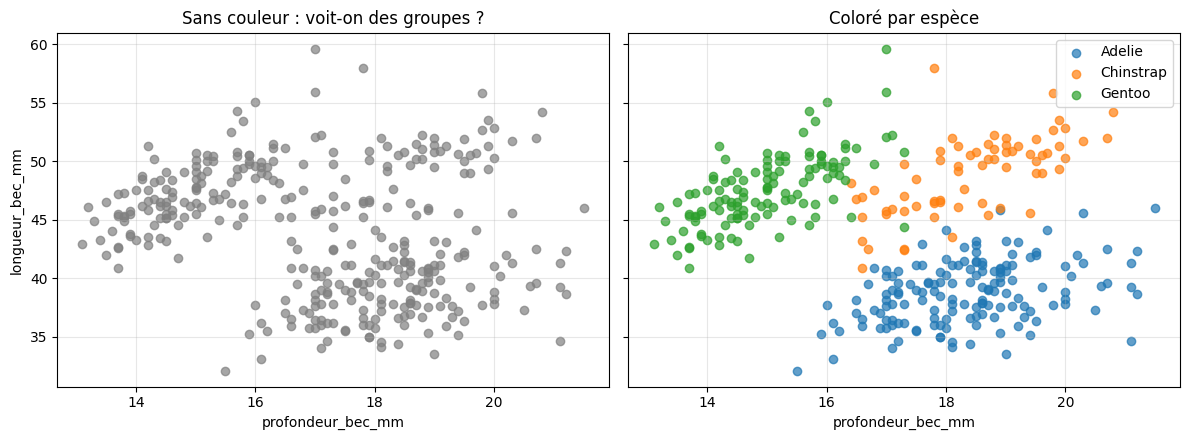

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)

# 1) sans couleur : la vision de K-means
ax[0].scatter(df[BEC_PROF], df[BEC_LONG], color="gray", alpha=0.7)
ax[0].set_title("Sans couleur : voit-on des groupes ?")

# 2) coloré par espèce : la vérité (cachée à K-means)
for esp, g in df.groupby(ESPECE):
    ax[1].scatter(g[BEC_PROF], g[BEC_LONG], label=esp, alpha=0.7)
ax[1].set_title("Coloré par espèce")
ax[1].legend()

for a in ax:
    a.set_xlabel(BEC_PROF)
    a.grid(alpha=0.3)
ax[0].set_ylabel(BEC_LONG)
plt.tight_layout()
plt.show()

✍️ **Ma réponse A.2** : *(combien de groupes voit-on sans couleur ? Une espèce est-elle nettement séparée des deux autres ?
Certaines espèces se chevauchent-elles sur ces deux variables seulement ?)*

---
# PARTIE B — K-means avec Python · 

## B.1 — Mettre à l'échelle
### Comparer les écarts-types
K-means repose sur des **distances**. Si une variable a des valeurs bien plus grandes que les autres,
c'est elle qui décide presque seule des groupes. Regardons les **écarts-types** des 4 mesures.

Écarts-types des mesures (unités d'origine) :
longueur_bec_mm           5.46
profondeur_bec_mm         1.97
longueur_nageoire_mm     14.06
masse_g                 801.95
dtype: float64

Rapport max / min = 406


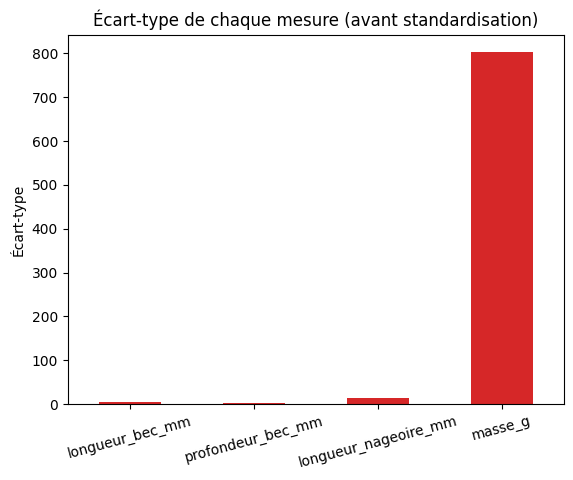

In [8]:
ecarts = df[MESURES].std()
print("Écarts-types des mesures (unités d'origine) :")
print(ecarts.round(2))
print(f"\nRapport max / min = {ecarts.max() / ecarts.min():.0f}")

ecarts.plot(kind="bar", color="tab:red", rot=15)
plt.title("Écart-type de chaque mesure (avant standardisation)")
plt.ylabel("Écart-type")
plt.show()

### Standardisation
`StandardScaler` transforme chaque variable : **z = (x − moyenne) / écart-type**. Après cela, chaque mesure a
**moyenne 0** et **écart-type 1** : toutes pèsent autant dans la distance.

In [9]:
scaler = StandardScaler()
X_std = scaler.fit_transform(df[MESURES])          # tableau numpy standardisé

verif = pd.DataFrame(X_std, columns=MESURES)
print("Moyennes après standardisation :", verif.mean().round(3).to_dict())
print("Écarts-types après standardisation :", verif.std().round(3).to_dict())

Moyennes après standardisation : {'longueur_bec_mm': 0.0, 'profondeur_bec_mm': -0.0, 'longueur_nageoire_mm': -0.0, 'masse_g': 0.0}
Écarts-types après standardisation : {'longueur_bec_mm': 1.001, 'profondeur_bec_mm': 1.001, 'longueur_nageoire_mm': 1.001, 'masse_g': 1.001}


✍️ **Ma réponse B.1** : écarts-types = *(…)*. **Pourquoi standardiser ?** La masse (en grammes) a un écart-type environ
*(…)* fois plus grand que celui des mesures en millimètres. Sans standardisation, les distances euclidiennes seraient
dominées par la masse, et les trois autres mesures compteraient presque pour rien. La standardisation donne le même poids à chaque mesure.

## B.2 — Choisir k
Le nombre de groupes k n'est pas connu à l'avance : on **teste k de 1 à 8** et on regarde deux indicateurs.

* **Inertie** (méthode du **coude**) : elle baisse toujours quand k augmente (plus de centres = points plus proches).
  On cherche le k où la baisse **ralentit nettement** (le « coude »).
* **Silhouette** (calculable à partir de k = 2) : on retient en général le k où elle est **maximale**.

`n_init=10` : K-means est relancé 10 fois avec des centres initiaux différents, on garde la meilleure solution
(le départ aléatoire peut donner de mauvais résultats). `random_state=0` : résultat reproductible.

,k,inertie,silhouette
0,1,1368.000,NaN
1,2,565.708,0.532
2,3,379.393,0.447
3,4,300.400,0.400
4,5,232.637,0.378
5,6,204.319,0.372
6,7,187.138,0.335
7,8,170.980,0.296


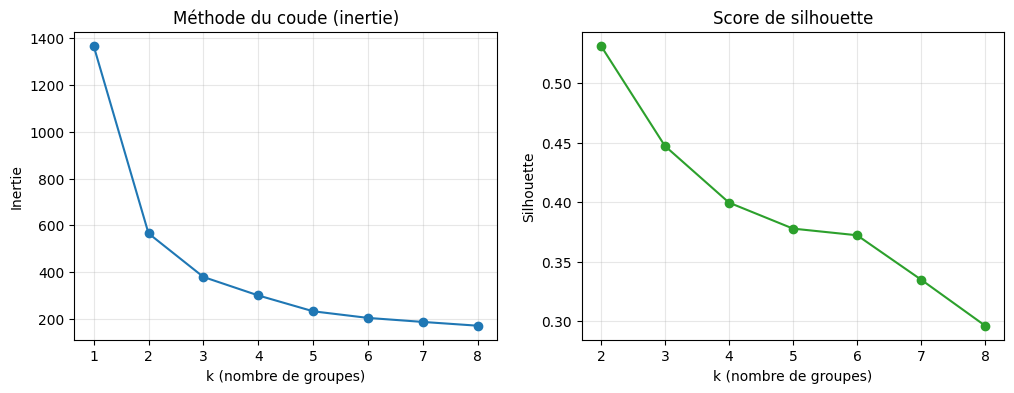

k qui maximise la silhouette : 2


In [10]:
inerties, silhouettes = [], []
valeurs_k = range(1, 9)

for k in valeurs_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_std)       # ENTRAÎNEMENT
    inerties.append(km.inertia_)
    silhouettes.append(silhouette_score(X_std, km.labels_) if k >= 2 else np.nan)

res_k = pd.DataFrame({"k": list(valeurs_k), "inertie": inerties, "silhouette": silhouettes})
display(res_k.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res_k["k"], res_k["inertie"], marker="o")
ax[0].set_title("Méthode du coude (inertie)")
ax[0].set_ylabel("Inertie")
ax[1].plot(res_k["k"], res_k["silhouette"], marker="o", color="tab:green")
ax[1].set_title("Score de silhouette")
ax[1].set_ylabel("Silhouette")
for a in ax:
    a.set_xlabel("k (nombre de groupes)")
    a.grid(alpha=0.3)
plt.show()

k_sil = int(res_k.loc[res_k["silhouette"].idxmax(), "k"])
print("k qui maximise la silhouette :", k_sil)

✍️ **Ma réponse B.2** : le coude apparaît vers k = *(…)* ; la silhouette est maximale pour k = *(…)*.
**k proposé : …**, car *(justifier avec les deux courbes ; le jeu contient 3 espèces mais la silhouette peut préférer 2
si deux espèces se chevauchent — à discuter)*.

## B.3 — Groupes et espèces (k = 3)
**But** : K-means n'a jamais vu les espèces. Les 3 groupes qu'il propose correspondent-ils aux 3 espèces ?

* `pd.crosstab` : tableau « groupe trouvé × vraie espèce ».
* **Indice de Rand ajusté (ARI)** : 1 = groupes identiques aux espèces, ~0 = hasard.

 Les numéros de groupes (0, 1, 2) sont **arbitraires** : le groupe « 0 » n'est pas forcément la première espèce.

In [11]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_std)
df["groupe"] = km3.labels_

tableau = pd.crosstab(df["groupe"], df[ESPECE])
display(tableau)

ari_std = adjusted_rand_score(df[ESPECE], df["groupe"])
print(f"Indice de Rand ajusté (données standardisées) = {ari_std:.3f}")

# Quelle espèce est la mieux isolée ? = celle dont presque tous les individus sont dans UN seul groupe
pureté = (tableau.max(axis=0) / tableau.sum(axis=0)).round(3)
print("\nPart de chaque espèce regroupée dans son groupe principal :")
print(pureté)
print("➡️ Espèce la mieux isolée :", pureté.idxmax())

espece,Adelie,Chinstrap,Gentoo
groupe,,,
0,0,0,123
1,127,5,0
2,24,63,0


Indice de Rand ajusté (données standardisées) = 0.793

Part de chaque espèce regroupée dans son groupe principal :
espece
Adelie       0.841
Chinstrap    0.926
Gentoo       1.000
dtype: float64
➡️ Espèce la mieux isolée : Gentoo


**Visualisation** : les groupes de K-means (couleurs) comparés aux vraies espèces (formes), avec les centres
(ramenés dans les unités d'origine grâce à `inverse_transform`).

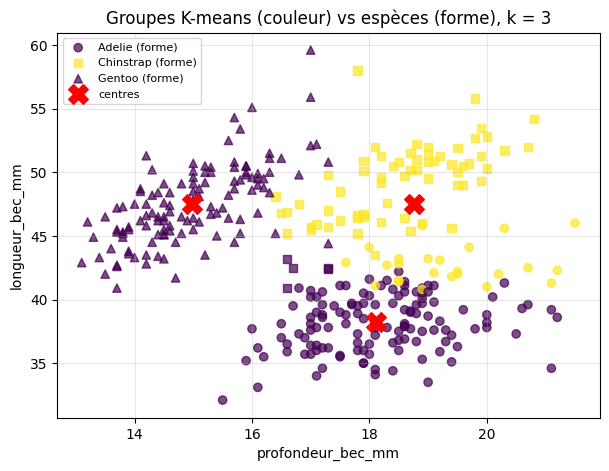

In [12]:
centres = scaler.inverse_transform(km3.cluster_centers_)           # centres en unités d'origine
i_l, i_p = MESURES.index(BEC_LONG), MESURES.index(BEC_PROF)

formes = dict(zip(sorted(df[ESPECE].unique()), ["o", "s", "^"]))
plt.figure(figsize=(7, 5))
for esp, g in df.groupby(ESPECE):
    plt.scatter(g[BEC_PROF], g[BEC_LONG], c=g["groupe"], cmap="viridis",
                marker=formes[esp], alpha=0.7, label=f"{esp} (forme)")
plt.scatter(centres[:, i_p], centres[:, i_l], c="red", marker="X", s=200, label="centres")
plt.xlabel(BEC_PROF); plt.ylabel(BEC_LONG)
plt.title("Groupes K-means (couleur) vs espèces (forme), k = 3")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

✍️ **Ma réponse B.3** : tableau croisé = *(recopier)* ; ARI = *(…)* ; espèce la mieux isolée = *(…)* car *(presque tous ses
individus tombent dans un seul groupe)*. Quelles espèces sont partiellement mélangées ? *(…)*

## B.4 — Et sans mise à l'échelle ?
On refait **exactement B.3** mais sur les données **brutes** (non standardisées), pour mesurer l'effet de la standardisation.

In [13]:
km3_brut = KMeans(n_clusters=3, n_init=10, random_state=0).fit(df[MESURES])
groupe_brut = km3_brut.labels_

display(pd.crosstab(groupe_brut, df[ESPECE], rownames=["groupe (brut)"]))

ari_brut = adjusted_rand_score(df[ESPECE], groupe_brut)
print(f"ARI avec standardisation    = {ari_std:.3f}")
print(f"ARI sans standardisation    = {ari_brut:.3f}")

# Rappel des écarts-types de B.1, pour l'explication
print("\nÉcarts-types bruts :")
print(df[MESURES].std().round(2))

espece,Adelie,Chinstrap,Gentoo
groupe (brut),,,
0,0,0,68
1,116,53,1
2,35,15,54


ARI avec standardisation    = 0.793
ARI sans standardisation    = 0.331

Écarts-types bruts :
longueur_bec_mm           5.46
profondeur_bec_mm         1.97
longueur_nageoire_mm     14.06
masse_g                 801.95
dtype: float64


✍️ **Ma réponse B.4** : l'ARI passe de *(…)* à *(…)*. **Explication** : sans standardisation, la variable ayant le plus grand
écart-type (la masse, en grammes, de l'ordre de *(…)*) domine les distances ; K-means découpe alors presque uniquement selon
la masse, et ignore l'information utile des mesures du bec. Les groupes ne correspondent donc plus aux espèces
(ex. Adelie et Chinstrap, de masses proches, sont mélangées).

## B.5 — Décrire les groupes
**Interprétation** : pour comprendre ce que représente chaque groupe, on calcule la **moyenne des 4 mesures par groupe**,
dans leurs **unités d'origine** (mm, g) et non en valeurs standardisées, pour pouvoir les lire.
Puis on donne un **nom** à chaque groupe.

In [14]:
profil = df.groupby("groupe")[MESURES].mean().round(1)
profil["effectif"] = df["groupe"].value_counts().sort_index()
# espèce dominante de chaque groupe (aide pour nommer)
profil["espèce dominante"] = pd.crosstab(df["groupe"], df[ESPECE]).idxmax(axis=1)
display(profil)

,longueur_bec_mm,profondeur_bec_mm,longueur_nageoire_mm,masse_g,effectif,espèce dominante
groupe,,,,,,
0,47.5,15.0,217.2,5076.0,123,Gentoo
1,38.2,18.1,188.4,3584.7,132,Adelie
2,47.5,18.8,196.9,3902.0,87,Chinstrap


✍️ **Ma réponse B.5** : proposer un nom par groupe, d'après ses moyennes. Exemple de raisonnement :
* **Groupe … — « … »** : *(ex. « les grands et lourds » : nageoires longues, masse élevée, bec peu profond → Gentoo)*
* **Groupe … — « … »** : *(…)*
* **Groupe … — « … »** : *(…)*

---
# PARTIE C — Avec Orange · 
**But** : refaire l'analyse avec un outil visuel et comparer avec la partie B.

### Workflow Orange à construire
`File (manchots.csv) → Select Columns → Preprocess (Normalize) → k-Means → Scatter Plot` et `k-Means → Distributions`

| Étape | Widget | Réglages et pourquoi |
|---|---|---|
| 1 | **File** puis **Select Columns** | Garder les **4 mesures** comme *features* ; mettre `espece` en **meta** (ainsi K-means ne la « voit » pas) |
| 2 | **Preprocess** | Cocher *Remove rows with missing values* (nettoyage) et *Normalize features* en choisissant **Standardize to μ=0, σ²=1** (standardisation) |
| 3 | **k-Means** | *Number of clusters* : **From 2 to 6** ; lire le **score de silhouette** de chaque k |
| 4 | **Scatter Plot** | Fixer **k = 3** ; axes : bec (longueur/profondeur) ; couleur = **Cluster** ; forme = **espece**. Comparer avec B.3 |

👉 Enregistrer en **`.ows`** (Fichier → Enregistrer) : c'est un livrable.

### Vérification en Python
Cette cellule recalcule les silhouettes pour k de 2 à 6 sur les données standardisées, pour comparer avec Orange
(de petites différences sont normales : initialisation et réglages internes différents ; **dans le rapport, on cite les valeurs d'Orange**).

In [15]:
lignes = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_std)
    lignes.append((k, round(silhouette_score(X_std, km.labels_), 3)))
display(pd.DataFrame(lignes, columns=["k", "silhouette (Python)"]))

,k,silhouette (Python)
0,2,0.532
1,3,0.447
2,4,0.400
3,5,0.378
4,6,0.372


✍️ **Ma réponse C** *(valeurs lues dans Orange)* :

| k | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|
| Silhouette (Orange) | | | | | |

* k qui maximise la silhouette dans Orange : *(…)* — est-ce le même qu'en B.2 ? *(…)*
* Scatter Plot à k = 3 : les groupes (couleurs) recoupent-ils les espèces (formes) comme dans le tableau croisé de B.3 ? *(…)*

---
#  Conclusion générale
* **K-means** trouve des groupes **sans connaître les espèces** ; ici, il en retrouve une grande partie *(ARI = …)*.
* **La standardisation est indispensable** : sans elle, la variable à grande échelle (la masse) domine et l'ARI s'effondre/diminue.
* **Choisir k** demande de croiser plusieurs indicateurs (coude, silhouette) et du bon sens : le meilleur k mathématique n'est pas
  toujours le nombre d'espèces réel.
* **Limites** : K-means suppose des groupes plutôt « ronds » et de tailles proches ; il dépend de l'initialisation (d'où `n_init`).

